# 이진 분류 실험 ② — 같은 쌍 반복 피처 추가 (pair history)
1단계 피처 사다리의 첫 칸. 01(기본 4 + port 2) 위에 **두 계좌 사이의 반복 거래** 피처 4개를 더한다. 모델은 GINe 고정, 나머지 설정은 01 과 동일.

| 피처 | 뜻 | 출처 |
|---|---|---|
| `pair_prior_count` | 이 거래 전에 같은 (src→dst) 로 보낸 횟수 (처음부터, 같은 분 제외) | v10 엣지 피처 |
| `pair_gap_minutes` | 직전 같은 쌍 거래까지의 분 (ln) | v10 |
| `pair_count_1h` | 최근 60분 안 같은 쌍 횟수 | v10 |
| `reverse_history_count` | 반대 방향 (dst→src) 누적 횟수 (전날까지) | v10 |

**가설**: 같은 상대에게 반복해서 보내거나(STACK, 반복 송금), 주고받는(BIPARTITE, 왕복) 패턴의 recall 이 오른다. FAN·CYCLE 은 거의 안 변해야 정상.

**누수 규칙**: 전부 거래 시각 기준 **과거**만 (v10 과 같이 같은 분은 제외). z-norm 은 학습 구간 통계. 공통 코드는 `bc_lib.py` (01 코드를 함수로 옮긴 것)

# 공통 부분 (작업 준비, 데이터 준비)

## 0. 작업 준비

In [4]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [5]:
# ---- 실험 설정 ------------------------------------------------------------
RUN_NAME = 'pair_history'         # results/<DATASET>/pair_history/
PREV_RUN = 'basic_features'       # 비교 기준 (01)
cfg = B.Config(dataset='HI-Large', smoke=False)
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)

# 이번 단계 피처
STAGE_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
STAGE_PATH = cfg.feat_dir / 'pair_history.parquet'
GNN_EDGE_FEATURES = B.BASIC_EDGE_FEATURES + B.PORT_FEATURES + STAGE_FEATURES     # FEAT16 열 순서. port 는 4,5 번
TREE_FEATURES = B.BASIC_EDGE_FEATURES + STAGE_FEATURES                           # 트리는 port 없이 (GFP "basic" + 이번 피처)
DEVICE, OUT_DIR, len(GNN_EDGE_FEATURES)

(device(type='cuda'),
 PosixPath('/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/pair_history'),
 10)

In [6]:
cfg

Config(dataset='HI-Large', smoke=False, val_neg_rate=0.02, scale_pos_weight=6, tree_rounds=500, tree_early_stop=20, num_neighbors=[100, 100], batch_size=2048, iter_per_epoch=256, epochs=400, eval_period=4, patience=8, class_weight=[1.0, 6.27], n_hidden=66, n_gnn_layers=2, lr=0.006, dropout=0.01, final_dropout=0.1, num_workers=0, seed=42)

## 1. 데이터 준비 — 거래 전체 + port

In [7]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # 있으면 건너뜀
tx = B.load_tx(con, cfg)
tx = B.attach_parquet(tx, PORTS_PATH, B.PORT_FEATURES)
tx.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(179702079, 11)

In [8]:
tx.head()

,edge_id,src,dst,day,timestamp,amount_received,received_currency,payment_format,y,in_port,out_port
0,1,3,3,2022-08-01,0.0,19.180000,12,5,0,0,0
1,2,25,78803,2022-08-01,0.0,17955.109375,12,3,0,0,0
2,3,31,86028,2022-08-01,0.0,1199.829956,12,2,0,0,0
3,4,39,269980,2022-08-01,0.0,148565.453125,12,6,0,0,0
4,5,50,29866,2022-08-01,0.0,227247.421875,12,3,0,0,0


## 2. 이번 단계 피처 계산 — 같은 쌍 반복

- DuckDB 창 함수. v10 `02_build_features` 의 SQL 과 같은 정의 (`EXCLUDE='1 minute'`, `HOUR_WINDOW='60 minutes'`)
- `pair_prior`/`pair_hour`: 같은 (src, dst) 파티션에서 거래 시각 기준 **1분 전까지** 센다 (같은 분 거래는 제외 — 서비스와 동일)
- `reverse_n`: 전날까지의 (dst→src) 누적 횟수. 일 단위 상태 테이블에 ASOF 조인 (v10 과 동일)
- 결과는 `features_bc/pair_history.parquet` 로 저장 (edge_id 순). 한 번 만들면 재사용. pandas 를 거치지 않는다

In [9]:
if not STAGE_PATH.exists():
    t0 = time.time()
    con.execute(f"""
        CREATE OR REPLACE TABLE tx_min AS
        SELECT edge_id, src, dst, ts, day FROM read_parquet({L.q(cfg.tx_path)})""")
    # (a) 같은 쌍 시간 창 (v10 cell 11 의 pair 부분)
    con.execute("""
        CREATE OR REPLACE TABLE pair_win AS
        SELECT edge_id, ts,
               count(*) OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_prior,
               max(ts)  OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN UNBOUNDED PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_last,
               count(*) OVER (PARTITION BY src, dst ORDER BY ts RANGE BETWEEN INTERVAL '60 minutes' PRECEDING AND INTERVAL '1 minute' PRECEDING) AS pair_hour
        FROM tx_min""")
    # (b) 반대 방향 누적 — 일 단위 상태 + ASOF (v10 cell 9)
    con.execute("""
        CREATE OR REPLACE TABLE pair_state AS
        SELECT src, dst, day, sum(n) OVER (PARTITION BY src, dst ORDER BY day ROWS UNBOUNDED PRECEDING) AS history_count
        FROM (SELECT src, dst, day, count(*) n FROM tx_min GROUP BY src, dst, day)""")
    con.execute("""
        CREATE OR REPLACE TABLE pairs AS
        SELECT t.src, t.dst, t.day, coalesce(r.history_count, 0) AS reverse_n
        FROM (SELECT DISTINCT src, dst, day FROM tx_min) t
        ASOF LEFT JOIN pair_state r ON t.src = r.dst AND t.dst = r.src AND t.day > r.day""")
    # (c) 변환 (ln) 후 저장
    con.execute(f"""
        COPY (
            SELECT t.edge_id,
                   ln(1 + w.pair_prior)::FLOAT                                                                       AS pair_prior_count,
                   (CASE WHEN w.pair_last IS NULL THEN 0 ELSE ln(2 + date_diff('minute', w.pair_last, t.ts)) END)::FLOAT AS pair_gap_minutes,
                   ln(1 + w.pair_hour)::FLOAT                                                                        AS pair_count_1h,
                   ln(1 + p.reverse_n)::FLOAT                                                                        AS reverse_history_count
            FROM tx_min t JOIN pair_win w USING (edge_id)
            JOIN pairs p ON t.src = p.src AND t.dst = p.dst AND t.day = p.day
            ORDER BY t.edge_id
        ) TO {L.q(STAGE_PATH)} (FORMAT PARQUET, COMPRESSION ZSTD)""")
    con.execute("DROP TABLE pair_win; DROP TABLE pair_state; DROP TABLE pairs; DROP TABLE tx_min")
    print(f'{STAGE_PATH.name} 생성 {time.time()-t0:.0f}s')
con.execute(f"SELECT count(*), {', '.join(f'avg({c}) AS avg_{c}' for c in STAGE_FEATURES)} FROM read_parquet({L.q(STAGE_PATH)})").df().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
count_star(),1.797021e+08
avg_pair_prior_count,3.745342e+00
avg_pair_gap_minutes,4.821949e+00
avg_pair_count_1h,3.787510e-01
avg_reverse_history_count,1.236571e-01


In [10]:
# 창 동작 확인 — 거래 8건에 가장 가까운 쌍 하나를 골라 타임라인으로 (prior 가 1씩 늘고, 같은 분은 안 세는지)
# 주의: 1.8억 건끼리 조인하면 메모리 초과 → 그 쌍의 edge_id 몇 개만 골라 피처 parquet 에서 읽는다
pair = con.execute(f"SELECT src, dst FROM read_parquet({L.q(cfg.tx_path)}) GROUP BY src, dst ORDER BY abs(count(*) - 8), src LIMIT 1").fetchone()
ids = con.execute(f"SELECT edge_id, ts FROM read_parquet({L.q(cfg.tx_path)}) WHERE src = {pair[0]} AND dst = {pair[1]} ORDER BY ts").df()
feat = con.execute(f"SELECT * FROM read_parquet({L.q(STAGE_PATH)}) WHERE edge_id IN ({', '.join(map(str, ids.edge_id))})").df()
ids.merge(feat, on='edge_id').sort_values('ts')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,edge_id,ts,pair_prior_count,pair_gap_minutes,pair_count_1h,reverse_history_count
0,43686,2022-08-01 00:01:00,0.000000,0.000000,0.000000,0.0
1,261708,2022-08-01 00:06:00,0.693147,1.945910,0.693147,0.0
2,56731886,2022-08-31 00:19:00,1.098612,10.673943,0.000000,0.0
3,57467372,2022-08-31 00:28:00,1.386294,2.397895,0.693147,0.0
4,110308037,2022-09-30 00:01:00,1.609438,10.673017,0.000000,0.0
5,111625969,2022-09-30 00:17:00,1.791759,2.890372,0.693147,0.0
6,166339798,2022-10-30 07:30:00,1.945910,10.683615,0.000000,0.0
7,166348467,2022-10-30 07:34:00,2.079442,1.791759,0.693147,0.0


In [11]:
tx = B.attach_parquet(tx, STAGE_PATH, STAGE_FEATURES)
tx[STAGE_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
pair_prior_count,179702079.0,3.745342,1.499816,0.0,2.944439,4.219508,4.859812,6.536692
pair_gap_minutes,179702079.0,4.821949,3.047155,0.0,2.079442,3.332205,7.430707,12.220321
pair_count_1h,179702079.0,0.378751,0.440044,0.0,0.000000,0.000000,0.693147,2.302585
reverse_history_count,179702079.0,0.123657,0.628591,0.0,0.000000,0.000000,0.000000,6.532334


In [12]:
# 라벨별 평균 — 세탁 거래에서 값이 다른가 (피처가 신호를 갖는지 미리 확인). pandas groupby 는 열 단위라 가볍다
tx.groupby('y')[STAGE_FEATURES].mean().T.rename(columns={0: 'normal', 1: 'laundering'})

y,normal,laundering
pair_prior_count,3.749042,0.801016
pair_gap_minutes,4.824810,2.545596
pair_count_1h,0.379175,0.041125
reverse_history_count,0.123430,0.304658


## 3. z-norm (학습 구간 통계) + 표본

In [13]:
in_train = B.window_mask(tx, cfg.train_window)
feat_z, znorm_table = B.znorm_features(tx, GNN_EDGE_FEATURES, in_train)     # tx 에서 피처 열은 떨어짐
znorm_table

,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,in_port,1.691504e+00,2.026216e+01
5,out_port,1.258211e+03,5.523149e+03
6,pair_prior_count,3.619840e+00,1.249556e+00
7,pair_gap_minutes,4.934093e+00,3.020734e+00
8,pair_count_1h,3.836407e-01,4.402390e-01
9,reverse_history_count,1.201977e-01,5.942421e-01


In [14]:
print(f"데이터 기간 {tx['day'].min().date()} ~ {tx['day'].max().date()}")
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

데이터 기간 2022-08-01 ~ 2023-01-12
train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [15]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 가중 표본 (05 공유)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
in_degree = B.recipient_indegree(con, cfg)                           # 분석용
con.close()

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
val_df.shape, test_df.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

((521382, 7), (26808230, 5))

# 트리 모델 (기본 4 + 이번 피처 4)

## 4. LightGBM / XGBoost

In [16]:
results = {}
tree_cols = [GNN_EDGE_FEATURES.index(c) for c in TREE_FEATURES]
train_mask = in_train
X_train = feat_z[train_mask][:, tree_cols]; y_train = tx['y'].to_numpy()[train_mask]
X_val, y_val, w_val = feat_z[val_idx][:, tree_cols], val_df['y'].to_numpy(), val_df['w'].to_numpy()
X_test = feat_z[test_idx][:, tree_cols]
if cfg.smoke:
    keep = np.random.default_rng(cfg.seed).choice(len(X_train), min(len(X_train), 200_000), replace=False)
    X_train, y_train = X_train[keep], y_train[keep]
X_train.shape, X_test.shape

((102336629, 8), (26808230, 8))

In [17]:
results['gine'] = json.load(open(OUT_DIR / 'results.json'))['results']['gine']

In [18]:
lgb_model, xgb_model = B.train_trees(X_train, y_train, X_val, y_val, w_val, X_test, val_df, test_df, cfg, results)
pd.DataFrame({'feature': TREE_FEATURES, 'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
              'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{i}', 0.0) for i in range(len(TREE_FEATURES))]})

/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[06:41:11] lightgbm val AP 0.3646
[06:53:05] xgboost  val AP 0.3543


,feature,lightgbm_gain,xgboost_gain
0,timestamp,7.142373e+05,143.785995
1,amount_received,4.729634e+06,1172.241943
2,received_currency,2.694989e+06,1295.118530
3,payment_format,4.952453e+06,6694.425293
4,pair_prior_count,1.819797e+06,4732.097168
5,pair_gap_minutes,1.024878e+06,275.634827
6,pair_count_1h,3.413944e+05,413.509430
7,reverse_history_count,1.503352e+06,489.003174


In [19]:
# 트리 테스트 점수도 저장 (분석용)
for name, model in [('lightgbm', lgb_model), ('xgboost', xgb_model)]:
    pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=model.predict_proba(X_test)[:, 1])).to_parquet(OUT_DIR / f'{name}_test_scores.parquet', index=False)
del X_train, y_train, X_test; gc.collect()
pd.DataFrame({k: v['val'] for k, v in results.items()}).T.round(4)

,AP,F1,F1_at_0.5,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE
gine,0.5140,0.5605,0.4714,0.6867,0.4735,0.8617,0.7562,0.4403,0.0034
lightgbm,0.3646,0.4853,0.4709,0.6408,0.3906,0.7421,0.6529,0.3983,0.0041
xgboost,0.3543,0.4900,0.4881,0.6475,0.3941,0.5787,0.6222,0.3519,0.0048


In [20]:
p = lgb_model.predict_proba(X_val)[:, 1]
print('best_it', lgb_model.best_iteration_, '| score==1 비율', (p >= 0.9999).mean().round(4), '| 그중 양성 비율', y_val[p >= 0.9999].mean().round(4))

best_it 319 | score==1 비율 0.0 | 그중 양성 비율 nan


/tmp/ipykernel_730639/3642301283.py:2: RuntimeWarning: Mean of empty slice
  print('best_it', lgb_model.best_iteration_, '| score==1 비율', (p >= 0.9999).mean().round(4), '| 그중 양성 비율', y_val[p >= 0.9999].mean().round(4))
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


# GNN (GINe, 01 과 같은 설정)

## 5. 그래프 — 한 번에 하나만 (bc_lib.GraphStore)

In [ ]:
store = B.GraphStore(tx, feat_z, cfg, train_rows=np.flatnonzero(train_mask), val_idx=val_idx, test_idx=test_idx,
                     port_cols=[GNN_EDGE_FEATURES.index('in_port'), GNN_EDGE_FEATURES.index('out_port')])
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.edge_dim

In [ ]:
# 배치 하나 꺼내서 모양 확인 — 2048 target 이 서브그래프 하나를 공유, 엣지 피처 10열
batch = next(iter(store.use('train')))
print('노드', batch['node'].num_nodes, ' to 간선', batch[B.TO].num_edges, ' rev_to 간선', batch[B.REV].num_edges,
      ' target', batch[B.TO].edge_label_index.shape[1], ' 양성', int(batch[B.TO].edge_label.sum()),
      ' x 열', batch['node'].x.shape[1], ' edge_attr 열', batch[B.TO].edge_attr.shape[1], ' target_attr', tuple(batch.target_attr.shape))

In [ ]:
# 모델 모양 확인
model = B.make_gine(store.edge_dim, cfg, edge_updates=False).to(DEVICE)
logits, labels = B.forward_batch(model, batch, DEVICE)
print('파라미터', sum(p.numel() for p in model.parameters()), ' 로짓', tuple(logits.shape))
del model, batch

## 6. 학습 — GINe

In [ ]:
gine_model, gine_hist = B.train_gnn('gine', store, cfg, val_df, OUT_DIR, DEVICE, edge_updates=False, results=results)
results['gine']['val']

In [ ]:
# 학습 곡선
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hv = gine_hist.dropna(subset=['AP']); ax[0].plot(hv['epoch'], hv['AP'], marker='o'); ax[1].plot(gine_hist['epoch'], gine_hist['train_loss'])
ax[0].set_title('val AP'); ax[1].set_title('train loss'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

## 7. 테스트 — 구간 전체

In [ ]:
gine_score = B.test_gnn('gine', store, cfg, test_df, OUT_DIR, DEVICE, edge_updates=False, results=results)

# 결과 — 저장된 점수 파일만으로 돌아간다
커널을 새로 켰으면 **0 절(설정 셀 3개)까지만** 돌리고 바로 여기부터. 재료는 `results/<DATASET>/<RUN_NAME>/`
- `{model}_test_scores.parquet` (edge_id, y, score) — 7 절·4 절에서 저장
- `results.json` — 검증/테스트 지표 (`results` dict 복구용)
- dst 와 수신자 in-degree 만 DuckDB 에서 다시 읽는다 (1~2 분)

운영점(컷)은 두 종류: **예산 컷** `r@b%` = 테스트 전체 상위 b% 를 알림으로 (0.05 / 0.1 / 0.5 / 1 / 2 / 5 / 10 % / all),
**argmax** = 확률 0.5 (논문 F1 운영점, Multi-GNN 부록 Table 13 의 패턴별 recall 과 같은 기준). 0.1% ≈ 양성 수 규모 ≈ argmax 와 비슷한 알림 수.

## 8. 준비 — 점수 · 라벨 · in-degree

In [21]:
import importlib; importlib.reload(B)
MODELS = [n for n in ['lightgbm', 'xgboost', 'gine'] if (OUT_DIR / f'{n}_test_scores.parquet').exists()]
scores = {n: B.load_scores(OUT_DIR / f'{n}_test_scores.parquet') for n in MODELS}
if 'test_df' not in globals() or 'in_degree' not in globals():
    con = L.connect(threads=8, memory='12GB')
    test_df = B.test_full(con, cfg.test_window); in_degree = B.recipient_indegree(con, cfg); con.close()
for n in MODELS:
    assert (scores[n]['edge_id'].to_numpy() == test_df['edge_id'].to_numpy()).all(), f'{n} 점수와 라벨 순서 불일치'
if 'results' not in globals() or not results:
    results = json.load(open(OUT_DIR / 'results.json'))['results']
print(MODELS, '| 테스트 간선', f"{len(test_df):,}", '| 양성', f"{int(test_df.y.sum()):,}", '| 컷', list(B.cut_thresholds(scores[MODELS[0]]['score'].to_numpy())))

['lightgbm', 'xgboost', 'gine'] | 테스트 간선 26,808,230 | 양성 34,460 | 컷 ['r@0.05%', 'r@0.1%', 'r@0.5%', 'r@1%', 'r@2%', 'r@5%', 'r@10%', 'all', 'argmax']


## 9. 운영점별 precision / recall
같은 점수를 컷만 바꿔 가며 본다. 예산을 줄이면 precision 이 오르고 recall 이 떨어지는 그 교환을 한 표에.

In [22]:
# 컷마다 임계값 · 알림 수 · TP/FP/FN · precision · recall (모델별). 'all' = 전부 알림 (precision = 양성 비율)
cut_df = pd.concat([B.cut_table(scores[n]).assign(model=n) for n in MODELS])
cut_df.to_csv(OUT_DIR / 'analysis_cuts.csv', encoding='utf-8-sig')
cut_df[cut_df.model == 'gine']

,threshold,alerts,TP,FP,FN,TN,precision,recall,model
cut,,,,,,,,,
r@0.05%,0.9889,13405,10818,2587,23642,26771183,0.8070,0.3139,gine
r@0.1%,0.9101,26809,16618,10191,17842,26763579,0.6199,0.4822,gine
r@0.5%,0.2677,134042,22190,111852,12270,26661918,0.1655,0.6439,gine
r@1%,0.1553,268083,26258,241825,8202,26531945,0.0979,0.7620,gine
r@2%,0.0272,536165,30003,506162,4457,26267608,0.0560,0.8707,gine
r@5%,0.0109,1340412,31466,1308946,2994,25464824,0.0235,0.9131,gine
r@10%,0.0061,2680823,33456,2647367,1004,24126403,0.0125,0.9709,gine
all,0.0000,26808230,34460,26773770,0,0,0.0013,1.0000,gine
argmax,0.5000,66538,19875,46663,14585,26727107,0.2987,0.5768,gine


In [23]:
# 모델 나란히 — 컷별 recall / precision
cut_df.reset_index().pivot(index='cut', columns='model', values=['recall', 'precision']).loc[cut_df.index.unique()]

recall                  precision                 
model      gine lightgbm xgboost      gine lightgbm xgboost
cut                                                        
r@0.05%  0.3139   0.3016  0.2865    0.8070   0.7414  0.7357
r@0.1%   0.4822   0.4201  0.4147    0.6199   0.5386  0.5331
r@0.5%   0.6439   0.5556  0.5413    0.1655   0.1428  0.1391
r@1%     0.7620   0.6721  0.6510    0.0979   0.0858  0.0819
r@2%     0.8707   0.8359  0.8200    0.0560   0.0537  0.0527
r@5%     0.9131   0.8974  0.8954    0.0235   0.0231  0.0230
r@10%    0.9709   0.9057  0.9023    0.0125   0.0116  0.0116
all      1.0000   1.0000  1.0000    0.0013   0.0013  0.0013
argmax   0.5768   0.4104  0.4008    0.2987   0.5903  0.6152

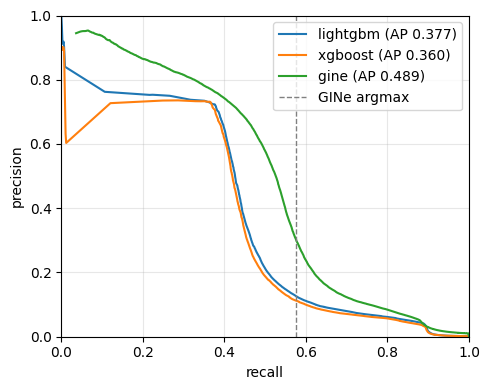

In [24]:
# PR 곡선 — 컷을 연속으로 훑은 것. AP = 곡선 아래 면적. 세로선 = GINe argmax 운영점
B.plot_pr(scores, path=OUT_DIR / 'pr_curve.png', mark=(cut_df.loc['argmax'].query("model == 'gine'")['recall'].iloc[0], 'GINe argmax'))

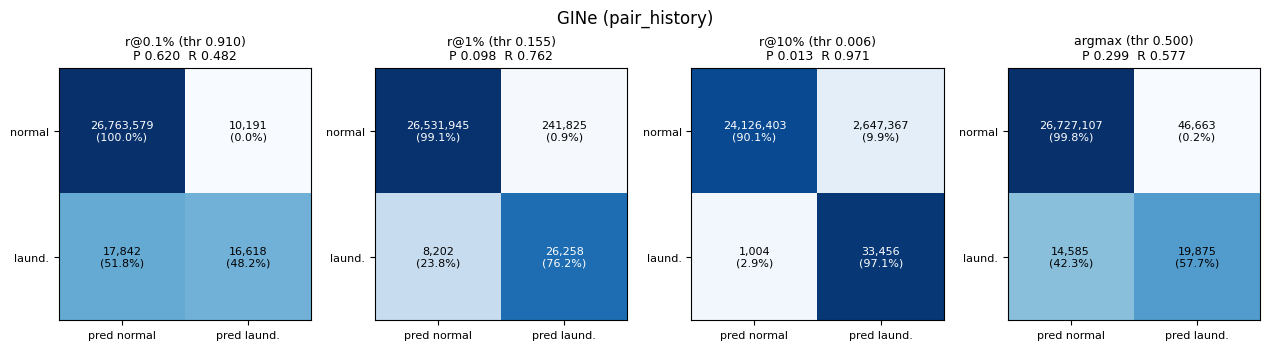

In [25]:
# 혼동행렬 — GINe, 컷 4개 나란히. 색 = 행 비율 (세탁 행 오른쪽 칸 = recall), 숫자 = 건수
B.plot_confusion_grid(scores['gine'], cuts=('r@0.1%', 'r@1%', 'r@10%', 'argmax'), title='GINe (pair_history)', path=OUT_DIR / 'confusion_cuts.png')

## 10. 패턴별 — 어느 패턴을 어느 컷에서 놓치나
패턴 안의 거래는 모두 양성이라 recall 만 본다. 예산을 줄일 때 먼저 떨어지는 패턴이 "모델이 덜 확신하는" 패턴.

In [26]:
# 패턴 × 컷 recall (모델별 저장, GINe 표시). 'recall' 열 = 1% (01 과 호환), mean_score = 그 패턴 양성의 평균 점수
pattern_df = pd.concat([B.pattern_recall(scores[n]).assign(model=n) for n in MODELS])
pattern_df.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig')
CUT_COLS = [c for c in pattern_df.columns if c.startswith('r@') or c in ('all', 'argmax')]
pattern_df[pattern_df.model == 'gine'][['n'] + CUT_COLS + ['mean_score']]

,n,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,mean_score
pattern_type,,,,,,,,,,,
FAN-OUT,2131,0.7363,0.9108,0.9784,0.9855,0.9972,0.9977,0.9977,1.0,0.9676,0.9553
FAN-IN,1922,0.3642,0.6909,0.9105,0.9282,0.9896,0.9969,0.9979,1.0,0.8673,0.8403
GATHER-SCATTER,3785,0.5929,0.8343,0.9543,0.9667,0.9966,0.9987,0.9989,1.0,0.9316,0.9151
SCATTER-GATHER,3891,0.5824,0.8365,0.9630,0.9733,0.9933,0.9949,0.9954,1.0,0.9350,0.9181
CYCLE,1853,0.5246,0.8386,0.9779,0.9838,0.9968,0.9978,0.9978,1.0,0.9644,0.9343
RANDOM,1335,0.5146,0.8210,0.9783,0.9865,0.9993,0.9993,0.9993,1.0,0.9581,0.9257
BIPARTITE,1833,0.4201,0.7545,0.9318,0.9460,0.9951,0.9962,0.9973,1.0,0.9018,0.8749
STACK,3437,0.4614,0.7894,0.9657,0.9767,0.9953,0.9962,0.9968,1.0,0.9389,0.9077
UNMATCHED,14273,0.0017,0.0133,0.1997,0.4692,0.6945,0.7945,0.9333,1.0,0.0726,0.1763


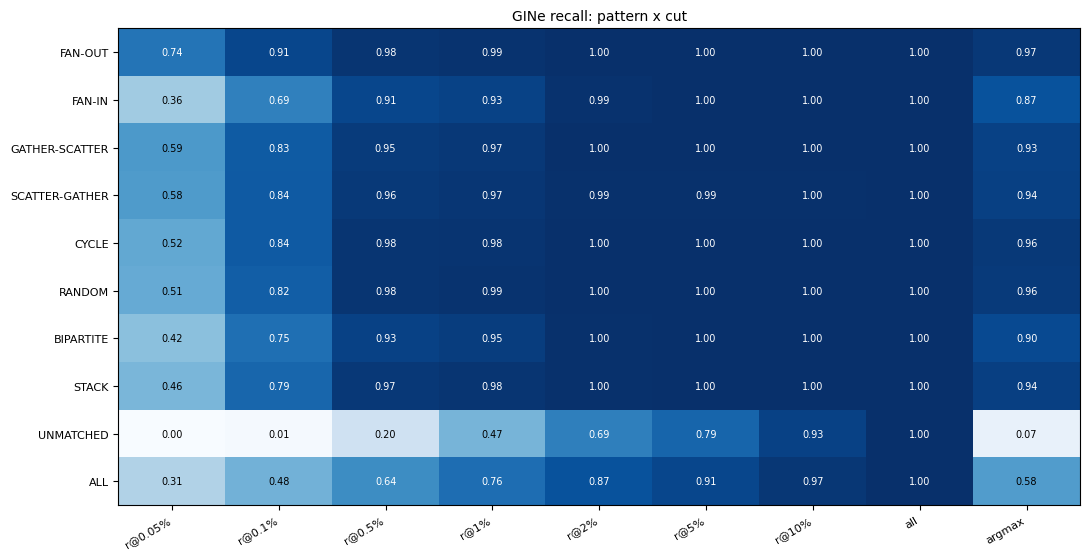

In [27]:
# 같은 표를 그림으로 — 행 = 패턴, 열 = 컷. 왼쪽(빡빡한 예산)에서 먼저 하얘지는 행이 약한 패턴
B.plot_heatmap(pattern_df[pattern_df.model == 'gine'][CUT_COLS], title='GINe recall: pattern x cut', path=OUT_DIR / 'pattern_x_cut.png')

In [28]:
# 놓친 세탁(FN) 의 구성 — 컷마다 FN 이 어느 패턴에서 나오나. FN% 가 pos_share 보다 크면 그 패턴을 유독 놓침
groups = dict(pattern=B.pattern_array(scores['gine']), degree_bin=B.degree_bin_of(test_df['dst'].to_numpy(), in_degree))
cb = B.confusion_breakdown(scores['gine'], groups)
for axis in groups:
    cb['fn'][axis].to_csv(OUT_DIR / f'analysis_fn_{axis}.csv', encoding='utf-8-sig'); cb['fp'][axis].to_csv(OUT_DIR / f'analysis_fp_{axis}.csv', encoding='utf-8-sig')
cb['fn']['pattern'][['pos_share'] + [c for c in cb['fn']['pattern'].columns if c.startswith('FN% ')]]

,pos_share,FN% r@0.05%,FN% r@0.1%,FN% r@0.5%,FN% r@1%,FN% r@2%,FN% r@5%,FN% r@10%,FN% all,FN% argmax
UNMATCHED,0.4142,0.6027,0.7893,0.9309,0.9237,0.9782,0.9796,0.9482,0.0,0.9076
SCATTER-GATHER,0.1129,0.0687,0.0356,0.0117,0.0127,0.0058,0.0067,0.0179,0.0,0.0173
GATHER-SCATTER,0.1098,0.0652,0.0351,0.0141,0.0154,0.0029,0.0017,0.0040,0.0,0.0178
STACK,0.0997,0.0783,0.0406,0.0096,0.0098,0.0036,0.0043,0.0110,0.0,0.0144
FAN-OUT,0.0618,0.0238,0.0106,0.0037,0.0038,0.0013,0.0017,0.0050,0.0,0.0047
FAN-IN,0.0558,0.0517,0.0333,0.0140,0.0168,0.0045,0.0020,0.0040,0.0,0.0175
CYCLE,0.0538,0.0373,0.0168,0.0033,0.0037,0.0013,0.0013,0.0040,0.0,0.0045
BIPARTITE,0.0532,0.0450,0.0252,0.0102,0.0121,0.0020,0.0023,0.0050,0.0,0.0123
RANDOM,0.0387,0.0274,0.0134,0.0024,0.0022,0.0002,0.0003,0.0010,0.0,0.0038


## 11. 수신자 in-degree 층화 (SALT-GNN 프로토콜)
허브(차수 큰 수신자) 쪽 거래가 약점인지. AP/F1 은 구간 안에서 따로 계산, recall/precision 은 전체 컷 임계값을 구간에 적용.

In [29]:
# 구간별 AP · F1 · 양성 비율 (모델별 저장, GINe 표시)
degree_df = pd.concat([B.degree_stratified(scores[n], test_df['dst'].to_numpy(), in_degree).assign(model=n) for n in MODELS])
degree_df.to_csv(OUT_DIR / 'analysis_degree.csv', encoding='utf-8-sig')
degree_df[degree_df.model == 'gine']

,n,n_pos,pos_rate,AP,F1,F1_at_0_5,recall_at_budget,recall_argmax,model
bin,,,,,,,,,
[1-4],232436,508,0.0022,0.7277,0.7086,0.6098,0.8740,0.7461,gine
[5-9],349131,2604,0.0075,0.7419,0.7269,0.6117,0.9109,0.7615,gine
[10-19],562520,4863,0.0086,0.4210,0.4800,0.3508,0.8234,0.5562,gine
[20-49],1102930,7132,0.0065,0.2763,0.3624,0.2558,0.7284,0.4563,gine
[50-99],893833,2493,0.0028,0.3826,0.4573,0.3006,0.6330,0.4565,gine
[100+],23667380,16860,0.0007,0.5507,0.6175,0.4646,0.7512,0.6178,gine


In [30]:
# 구간 × 컷 — recall 과 precision (GINe). 같은 임계값인데 구간마다 precision 이 다르면 알림이 그쪽에 몰리는 것
deg_cut = B.group_by_cut(scores['gine'], groups['degree_bin'])
order = [b for b in [f'[{lo}-{hi}]' if hi < 10**9 else f'[{lo}+]' for lo, hi in B.DEGREE_BINS] if b in deg_cut['recall'].index]
deg_cut['recall'].loc[order].to_csv(OUT_DIR / 'analysis_degree_x_cut_recall.csv', encoding='utf-8-sig')
deg_cut['precision'].loc[order].to_csv(OUT_DIR / 'analysis_degree_x_cut_precision.csv', encoding='utf-8-sig')
display(deg_cut['recall'].loc[order]); deg_cut['precision'].loc[order]

,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,n_pos
[1-4],0.5138,0.6476,0.7815,0.8740,0.9705,0.9764,0.9803,1.0,0.7461,508
[5-9],0.4988,0.6544,0.8053,0.9109,0.9908,0.9931,0.9939,1.0,0.7615,2604
[10-19],0.2077,0.4107,0.6564,0.8234,0.9848,0.9920,0.9934,1.0,0.5562,4863
[20-49],0.1270,0.3145,0.5735,0.7284,0.9476,0.9863,0.9920,1.0,0.4563,7132
[50-99],0.2796,0.3871,0.5319,0.6330,0.8227,0.9065,0.9458,1.0,0.4565,2493
[100+],0.3941,0.5563,0.6577,0.7512,0.7907,0.8461,0.9553,1.0,0.6178,16860


,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,n_pos
[1-4],0.8818,0.7651,0.3437,0.2017,0.1167,0.1107,0.1088,0.0022,0.5156,508
[5-9],0.9180,0.8095,0.3141,0.1590,0.1031,0.0986,0.0969,0.0075,0.5111,2604
[10-19],0.7799,0.5725,0.1242,0.0710,0.0434,0.0406,0.0401,0.0086,0.2562,4863
[20-49],0.6376,0.4227,0.0996,0.0666,0.0361,0.0268,0.0252,0.0065,0.1777,7132
[50-99],0.7415,0.5239,0.1361,0.0878,0.0377,0.0195,0.0141,0.0028,0.2241,2493
[100+],0.8267,0.6878,0.2230,0.1286,0.0861,0.0176,0.0077,0.0007,0.3723,16860


In [31]:
# 잘못 잡은 정상(FP) 이 어느 차수 구간에 몰리나 — FP% 가 neg_share 보다 크면 그 구간에 알림이 과함
cb['fp']['degree_bin'][['neg_share'] + [c for c in cb['fp']['degree_bin'].columns if c.startswith('FP% ')]]

,neg_share,FP% r@0.05%,FP% r@0.1%,FP% r@0.5%,FP% r@1%,FP% r@2%,FP% r@5%,FP% r@10%,FP% all,FP% argmax
[100+],0.8833,0.5385,0.4178,0.3453,0.3550,0.2794,0.6099,0.7801,0.8833,0.3764
[20-49],0.0409,0.1991,0.3006,0.3305,0.3012,0.3565,0.1953,0.1035,0.0409,0.3226
[50-99],0.0333,0.0939,0.0861,0.0753,0.0678,0.1035,0.0867,0.0621,0.0333,0.0844
[10-19],0.0208,0.1102,0.1463,0.2011,0.2168,0.2088,0.0870,0.0437,0.0208,0.1683
[5-9],0.0129,0.0448,0.0393,0.0409,0.0519,0.0444,0.0181,0.0091,0.0129,0.0407
[1-4],0.0087,0.0135,0.0099,0.0068,0.0073,0.0074,0.0030,0.0015,0.0087,0.0076


## 12. 01 (basic_features) 과 비교
01 쪽 표는 `analysis_01.ipynb` 가 만든다. 없으면 건너뛴다.

In [32]:
# 패턴별 recall — 1% 와 argmax 두 컷에서 01 GINe basic vs 이번 GINe
prev_path = Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_pattern.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0); prev = prev[prev.model == 'gine_basic']; cur = pattern_df[pattern_df.model == 'gine']
    cols = {'01 r@1%': prev['recall'], '02 r@1%': cur['recall']}
    if 'argmax' in prev.columns:
        cols.update({'01 argmax': prev['argmax'], '02 argmax': cur['argmax']})
    cmp = pd.DataFrame(cols); cmp['diff r@1%'] = cmp['02 r@1%'] - cmp['01 r@1%']
    if 'argmax' in prev.columns: cmp['diff argmax'] = cmp['02 argmax'] - cmp['01 argmax']
    display(cmp.loc[[p for p in B.PATTERN_ORDER + ['ALL'] if p in cmp.index]].round(4))
else:
    print('01 분석표 없음 — analysis_01.ipynb 를 먼저 돌리면 비교가 나온다:', prev_path)

,01 r@1%,02 r@1%,diff r@1%
pattern_type,,,
FAN-OUT,0.9840,0.9855,0.0015
FAN-IN,0.9485,0.9282,-0.0203
GATHER-SCATTER,0.9609,0.9667,0.0058
SCATTER-GATHER,0.9758,0.9733,-0.0025
CYCLE,0.9665,0.9838,0.0173
RANDOM,0.9648,0.9865,0.0217
BIPARTITE,0.9525,0.9460,-0.0065
STACK,0.9630,0.9767,0.0137
UNMATCHED,0.4324,0.4692,0.0368


In [33]:
# 수신 계좌 degree 구간별 AP — 허브 구간이 달라졌나
prev_path = Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_degree.csv'
if prev_path.exists():
    prev_d = pd.read_csv(prev_path, index_col=0); prev_d = prev_d[prev_d.model == 'gine_basic']; cur_d = degree_df[degree_df.model == 'gine']
    display(pd.DataFrame({'01 AP': prev_d['AP'], '02 AP': cur_d['AP'], 'diff': cur_d['AP'] - prev_d['AP'],
                          '01 F1': prev_d['F1'], '02 F1': cur_d['F1'], 'n_pos': cur_d['n_pos']}).round(4))
else:
    print('01 분석표 없음:', prev_path)

,01 AP,02 AP,diff,01 F1,02 F1,n_pos
bin,,,,,,
[1-4],0.7499,0.7277,-0.0222,0.7077,0.7086,508
[5-9],0.7259,0.7419,0.0160,0.7011,0.7269,2604
[10-19],0.3906,0.4210,0.0304,0.4316,0.4800,4863
[20-49],0.2716,0.2763,0.0047,0.3280,0.3624,7132
[50-99],0.2883,0.3826,0.0943,0.3768,0.4573,2493
[100+],0.3878,0.5507,0.1629,0.5123,0.6175,16860


## 13. 비교표 + 저장

In [34]:
compare_df = B.save_results(OUT_DIR, cfg, results, features=dict(tree=TREE_FEATURES, gnn=GNN_EDGE_FEATURES))
compare_df

AP      F1  F1_at_0.5  precision  recall  recall_at_1pct  \
model    split                                                                 
gine     val    0.5140  0.5605     0.4714     0.6867  0.4735          0.7562   
         test   0.4889  0.5452     0.3936     0.6595  0.4647          0.7620   
lightgbm val    0.3646  0.4853     0.4709     0.6408  0.3906          0.6529   
         test   0.3768  0.4976     0.4842     0.6992  0.3862          0.6706   
xgboost  val    0.3543  0.4900     0.4881     0.6475  0.3941          0.6222   
         test   0.3595  0.4915     0.4854     0.7059  0.3770          0.6452   

                unmatched_recall_at_1pct     ECE  train_sec  
model    split                                               
gine     val                      0.4403  0.0034      58202  
         test                     0.4692  0.0043      58202  
lightgbm val                      0.3983  0.0041       1189  
         test                     0.4335  0.0039       1189  
xgboost  val                      0.3519  0.0048        714  
         test                     0.3956  0.0044        714

In [35]:
# 01 전체 지표와 나란히
prev_c = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'compare.csv', index_col=[0, 1])
pd.concat([prev_c.assign(run=PREV_RUN), compare_df.assign(run=RUN_NAME)]).reset_index().set_index(['run', 'model', 'split'])[['AP', 'F1', 'F1_at_0.5', 'recall_at_1pct', 'unmatched_recall_at_1pct']]

AP      F1  F1_at_0.5  \
run            model          split                              
basic_features lightgbm_basic val    0.0486  0.1230     0.1131   
                              test   0.0455  0.1166     0.1074   
               xgboost_basic  val    0.0561  0.1301     0.1272   
                              test   0.0511  0.1221     0.1187   
               gine_basic     val    0.4614  0.5182     0.4842   
                              test   0.3934  0.4716     0.4138   
               gine_eu_basic  val    0.4145  0.4550     0.4529   
                              test   0.2338  0.3375     0.3205   
pair_history   gine           val    0.5140  0.5605     0.4714   
                              test   0.4889  0.5452     0.3936   
               lightgbm       val    0.3646  0.4853     0.4709   
                              test   0.3768  0.4976     0.4842   
               xgboost        val    0.3543  0.4900     0.4881   
                              test   0.3595  0.4915     0.4854   

                                     recall_at_1pct  unmatched_recall_at_1pct  
run            model          split                                            
basic_features lightgbm_basic val            0.4389                    0.0696  
                              test           0.4412                    0.0789  
               xgboost_basic  val            0.4435                    0.0638  
                              test           0.4446                    0.0712  
               gine_basic     val            0.7447                    0.4265  
                              test           0.7447                    0.4324  
               gine_eu_basic  val            0.7208                    0.3860  
                              test           0.6695                    0.2955  
pair_history   gine           val            0.7562                    0.4403  
                              test           0.7620                    0.4692  
               lightgbm       val            0.6529                    0.3983  
                              test           0.6706                    0.4335  
               xgboost        val            0.6222                    0.3519  
                              test           0.6452                    0.3956

In [36]:
sorted(p.name for p in OUT_DIR.iterdir())   # 이 폴더가 report.md 의 재료

['analysis_budget_table.csv',
 'analysis_confusion.csv',
 'analysis_confusion_pattern.csv',
 'analysis_cuts.csv',
 'analysis_degree.csv',
 'analysis_degree_x_cut_precision.csv',
 'analysis_degree_x_cut_recall.csv',
 'analysis_fn_degree_bin.csv',
 'analysis_fn_pattern.csv',
 'analysis_fp_degree_bin.csv',
 'analysis_fp_pattern.csv',
 'analysis_pattern.csv',
 'analysis_pr_table.csv',
 'compare.csv',
 'confusion.png',
 'confusion_cuts.png',
 'confusion_pattern.png',
 'curves.png',
 'gine.pt',
 'gine_history.csv',
 'gine_test_scores.parquet',
 'lightgbm_test_scores.parquet',
 'pattern_x_cut.png',
 'pr_curve.png',
 'results.json',
 'xgboost_test_scores.parquet']

## 14. 다음
- 03: 계좌 단기 활동 (sender/receiver 1h·1일 거래 수·상대 수·금액 합) → FAN-IN/OUT, GATHER-SCATTER
- 04: 계좌 금액 분포 (1일 창 mean/std/max) → 스머핑, 허브 구별
- 05: GFP 모티프 (사이클·scatter-gather 참여 수) → CYCLE, SCATTER-GATHER